# Bank Marketing — EDA

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = "../dataset/bank/bank-full.csv"

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


# 1. Data Understanding

## 1.1 Load

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";")
df_raw.shape

(45211, 17)

## 1.2 Overview — raw data

In [3]:
df_raw.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
pd.DataFrame({
    "dtype": df_raw.dtypes,
    "n_unique": df_raw.nunique(),
    "n_missing": df_raw.isna().sum(),
    "sample_values": [df_raw[c].unique()[:5] for c in df_raw.columns],
})

,dtype,n_unique,n_missing,sample_values
age,int64,77,0,"[58, 44, 33, 47, 35]"
job,str,12,0,"[management, technician, entrepreneur, blue-collar, unknown]"
marital,str,3,0,"[married, single, divorced]"
education,str,4,0,"[tertiary, secondary, unknown, primary]"
default,str,2,0,"[no, yes]"
balance,int64,7168,0,"[2143, 29, 2, 1506, 1]"
housing,str,2,0,"[yes, no]"
loan,str,2,0,"[no, yes]"
contact,str,3,0,"[unknown, cellular, telephone]"
day,int64,31,0,"[5, 6, 7, 8, 9]"


## 1.3 Column mapping

In [5]:
COLUMN_MAP = {
    "default": "has_credit_default",           # has credit in default? (yes/no)
    "balance": "avg_yearly_balance",           # average yearly balance (euros)
    "housing": "has_housing_loan",             # has housing loan? (yes/no)
    "loan": "has_personal_loan",               # has personal loan? (yes/no)
    "contact": "contact_type",                 # contact communication type: cellular / telephone / unknown
    "day": "last_contact_day",                 # last contact day of month
    "month": "last_contact_month",             # last contact month of year
    "duration": "last_contact_duration",       # last contact duration (seconds); leakage, benchmark only
    "campaign": "n_contacts_this_campaign",    # contacts during this campaign (incl. last contact)
    "pdays": "days_since_prev_campaign",       # days since last contact in a previous campaign (-1 = never)
    "previous": "n_contacts_before_campaign",  # contacts before this campaign
    "poutcome": "prev_campaign_outcome",       # outcome of the previous campaign
    "y": "subscribed_term_deposit",            # target: has the client subscribed a term deposit?
}

df = df_raw.rename(columns=COLUMN_MAP)

## 1.4 Convert yes/no to 1/0

In [6]:
YES_NO_COLS = ["has_credit_default", "has_housing_loan", "has_personal_loan", "subscribed_term_deposit"]

for col in YES_NO_COLS:
    df[col] = df[col].map({"yes": 1, "no": 0})

In [7]:
df[YES_NO_COLS].head()

,has_credit_default,has_housing_loan,has_personal_loan,subscribed_term_deposit
0,0,1,0,0
1,0,1,0,0
2,0,1,1,0
3,0,1,0,0
4,0,0,0,0


## 1.5 Overview — new data

In [8]:
df.shape

(45211, 17)

In [9]:
df.head()

,age,job,marital,education,has_credit_default,avg_yearly_balance,has_housing_loan,has_personal_loan,contact_type,last_contact_day,last_contact_month,last_contact_duration,n_contacts_this_campaign,days_since_prev_campaign,n_contacts_before_campaign,prev_campaign_outcome,subscribed_term_deposit
0,58,management,married,tertiary,0,2143,1,0,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,0,29,1,0,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,0,2,1,1,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,0,1506,1,0,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,0,1,0,0,unknown,5,may,198,1,-1,0,unknown,0


In [10]:
df.tail()

,age,job,marital,education,has_credit_default,avg_yearly_balance,has_housing_loan,has_personal_loan,contact_type,last_contact_day,last_contact_month,last_contact_duration,n_contacts_this_campaign,days_since_prev_campaign,n_contacts_before_campaign,prev_campaign_outcome,subscribed_term_deposit
45206,51,technician,married,tertiary,0,825,0,0,cellular,17,nov,977,3,-1,0,unknown,1
45207,71,retired,divorced,primary,0,1729,0,0,cellular,17,nov,456,2,-1,0,unknown,1
45208,72,retired,married,secondary,0,5715,0,0,cellular,17,nov,1127,5,184,3,success,1
45209,57,blue-collar,married,secondary,0,668,0,0,telephone,17,nov,508,4,-1,0,unknown,0
45210,37,entrepreneur,married,secondary,0,2971,0,0,cellular,17,nov,361,2,188,11,other,0


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   age                         45211 non-null  int64
 1   job                         45211 non-null  str  
 2   marital                     45211 non-null  str  
 3   education                   45211 non-null  str  
 4   has_credit_default          45211 non-null  int64
 5   avg_yearly_balance          45211 non-null  int64
 6   has_housing_loan            45211 non-null  int64
 7   has_personal_loan           45211 non-null  int64
 8   contact_type                45211 non-null  str  
 9   last_contact_day            45211 non-null  int64
 10  last_contact_month          45211 non-null  str  
 11  last_contact_duration       45211 non-null  int64
 12  n_contacts_this_campaign    45211 non-null  int64
 13  days_since_prev_campaign    45211 non-null  int64
 14  n_contacts_before

In [12]:
df.describe(include="all")

,age,job,marital,education,has_credit_default,avg_yearly_balance,has_housing_loan,has_personal_loan,contact_type,last_contact_day,last_contact_month,last_contact_duration,n_contacts_this_campaign,days_since_prev_campaign,n_contacts_before_campaign,prev_campaign_outcome,subscribed_term_deposit
count,45211.000000,45211,45211,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211.000000
unique,NaN,12,3,4,NaN,NaN,NaN,NaN,3,NaN,12,NaN,NaN,NaN,NaN,4,NaN
top,NaN,blue-collar,married,secondary,NaN,NaN,NaN,NaN,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,NaN
freq,NaN,9732,27214,23202,NaN,NaN,NaN,NaN,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,NaN
mean,40.936210,NaN,NaN,NaN,0.018027,1362.272058,0.555838,0.160226,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,0.116985
std,10.618762,NaN,NaN,NaN,0.133049,3044.765829,0.496878,0.366820,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,0.321406
min,18.000000,NaN,NaN,NaN,0.000000,-8019.000000,0.000000,0.000000,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,0.000000
25%,33.000000,NaN,NaN,NaN,0.000000,72.000000,0.000000,0.000000,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,0.000000
50%,39.000000,NaN,NaN,NaN,0.000000,448.000000,1.000000,0.000000,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,0.000000
75%,48.000000,NaN,NaN,NaN,0.000000,1428.000000,1.000000,0.000000,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,0.000000


In [13]:
pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    # categorical: all unique values, numeric: first 5
    "values": [df[c].unique()[:5] if pd.api.types.is_numeric_dtype(df[c]) else df[c].unique() for c in df.columns],
})

,dtype,n_unique,n_missing,values
age,int64,77,0,"[58, 44, 33, 47, 35]"
job,str,12,0,"[management, technician, entrepreneur, blue-collar, unknown, retired, admin., services, self-employed, unemployed, housemaid, student]"
marital,str,3,0,"[married, single, divorced]"
education,str,4,0,"[tertiary, secondary, unknown, primary]"
has_credit_default,int64,2,0,"[0, 1]"
avg_yearly_balance,int64,7168,0,"[2143, 29, 2, 1506, 1]"
has_housing_loan,int64,2,0,"[1, 0]"
has_personal_loan,int64,2,0,"[0, 1]"
contact_type,str,3,0,"[unknown, cellular, telephone]"
last_contact_day,int64,31,0,"[5, 6, 7, 8, 9]"


### Variables

In [14]:
VARIABLES = pd.DataFrame(
    [
        ("age", "numerical", "age (years)"),
        ("job", "categorical", "type of job"),
        ("marital", "categorical", "marital status ('divorced' = divorced or widowed)"),
        ("education", "categorical", "education level"),
        ("has_credit_default", "categorical", "has credit in default?"),
        ("avg_yearly_balance", "numerical", "average yearly balance (euros)"),
        ("has_housing_loan", "categorical", "has housing loan?"),
        ("has_personal_loan", "categorical", "has personal loan?"),
        ("contact_type", "categorical", "contact communication type"),
        ("last_contact_day", "datetime", "last contact day of month"),
        ("last_contact_month", "datetime", "last contact month of year"),
        ("last_contact_duration", "numerical", "last contact duration (seconds); known only after the call"),
        ("n_contacts_this_campaign", "numerical", "contacts during this campaign (incl. last contact)"),
        ("days_since_prev_campaign", "numerical", "days since last contact in a previous campaign (-1 = never)"),
        ("n_contacts_before_campaign", "numerical", "contacts before this campaign"),
        ("prev_campaign_outcome", "categorical", "outcome of the previous campaign"),
        ("subscribed_term_deposit", "categorical", "has the client subscribed a term deposit? (target)"),
    ],
    columns=["column", "type", "meaning"],
).set_index("column")
VARIABLES

,type,meaning
column,,
age,numerical,age (years)
job,categorical,type of job
marital,categorical,marital status ('divorced' = divorced or widowed)
education,categorical,education level
has_credit_default,categorical,has credit in default?
avg_yearly_balance,numerical,average yearly balance (euros)
has_housing_loan,categorical,has housing loan?
has_personal_loan,categorical,has personal loan?
contact_type,categorical,contact communication type


In [15]:
VARIABLES["type"].value_counts()

type
categorical    9
numerical      6
datetime       2
Name: count, dtype: int64

### Target

In [16]:
TARGET = "subscribed_term_deposit"
df[TARGET].value_counts()

subscribed_term_deposit
0    39922
1     5289
Name: count, dtype: int64

# 2. Data Quality

## 2.1 Missing values

In [17]:
df.isnull().sum()

age                           0
job                           0
marital                       0
education                     0
has_credit_default            0
avg_yearly_balance            0
has_housing_loan              0
has_personal_loan             0
contact_type                  0
last_contact_day              0
last_contact_month            0
last_contact_duration         0
n_contacts_this_campaign      0
days_since_prev_campaign      0
n_contacts_before_campaign    0
prev_campaign_outcome         0
subscribed_term_deposit       0
dtype: int64

## 2.2 `unknown` values

In [18]:
is_unknown = df == "unknown"
pd.DataFrame({"count": is_unknown.sum(), "pct": is_unknown.mean() * 100}).query("count > 0")

,count,pct
job,288,0.637013
education,1857,4.107407
contact_type,13020,28.798301
prev_campaign_outcome,36959,81.747805


## 2.3 Duplicates

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.drop(columns=TARGET).duplicated().sum()

np.int64(0)

## 2.4 Invalid values

In [21]:
# number of rows per condition
pd.Series({
    "age not in 18..100": (~df["age"].between(18, 100)).sum(),
    "last_contact_day not in 1..31": (~df["last_contact_day"].between(1, 31)).sum(),
    "n_contacts_this_campaign < 1": (df["n_contacts_this_campaign"] < 1).sum(),
    "n_contacts_before_campaign < 0": (df["n_contacts_before_campaign"] < 0).sum(),
    "days_since_prev_campaign == 0 or < -1": ((df["days_since_prev_campaign"] == 0) | (df["days_since_prev_campaign"] < -1)).sum(),
    "last_contact_duration == 0": (df["last_contact_duration"] == 0).sum(),
    "avg_yearly_balance < 0": (df["avg_yearly_balance"] < 0).sum(),
    "days_since_prev_campaign == -1": (df["days_since_prev_campaign"] == -1).sum(),
})

age not in 18..100                           0
last_contact_day not in 1..31                0
n_contacts_this_campaign < 1                 0
n_contacts_before_campaign < 0               0
days_since_prev_campaign == 0 or < -1        0
last_contact_duration == 0                   3
avg_yearly_balance < 0                    3766
days_since_prev_campaign == -1           36954
dtype: int64

In [22]:
df[df["last_contact_duration"] == 0]

,age,job,marital,education,has_credit_default,avg_yearly_balance,has_housing_loan,has_personal_loan,contact_type,last_contact_day,last_contact_month,last_contact_duration,n_contacts_this_campaign,days_since_prev_campaign,n_contacts_before_campaign,prev_campaign_outcome,subscribed_term_deposit
6424,53,management,married,primary,0,351,1,0,unknown,27,may,0,4,-1,0,unknown,0
22937,35,technician,married,secondary,0,5535,0,0,cellular,26,aug,0,15,-1,0,unknown,0
36425,31,entrepreneur,married,secondary,0,162,1,1,cellular,11,may,0,2,-1,0,unknown,0


## 2.5 Inconsistent values

In [23]:
never_contacted = df["days_since_prev_campaign"] == -1
pd.crosstab(never_contacted, df["n_contacts_before_campaign"] == 0)

n_contacts_before_campaign,False,True
days_since_prev_campaign,,
False,8257,0
True,0,36954


In [24]:
pd.crosstab(df["prev_campaign_outcome"], never_contacted)

days_since_prev_campaign,False,True
prev_campaign_outcome,,
failure,4901,0
other,1840,0
success,1511,0
unknown,5,36954


## 2.6 Outliers

In [25]:
NUMERIC_COLS = [
    "age",
    "avg_yearly_balance",
    "last_contact_duration",
    "n_contacts_this_campaign",
    "days_since_prev_campaign",
    "n_contacts_before_campaign",
]

q1 = df[NUMERIC_COLS].quantile(0.25)
q3 = df[NUMERIC_COLS].quantile(0.75)
lower = q1 - 1.5 * (q3 - q1)
upper = q3 + 1.5 * (q3 - q1)
is_outlier = (df[NUMERIC_COLS] < lower) | (df[NUMERIC_COLS] > upper)

pd.DataFrame({"lower": lower, "upper": upper, "count": is_outlier.sum(), "pct": is_outlier.mean() * 100})

,lower,upper,count,pct
age,10.5,70.5,487,1.077171
avg_yearly_balance,-1962.0,3462.0,4729,10.459844
last_contact_duration,-221.0,643.0,3235,7.155338
n_contacts_this_campaign,-2.0,6.0,3064,6.777112
days_since_prev_campaign,-1.0,-1.0,8257,18.263255
n_contacts_before_campaign,0.0,0.0,8257,18.263255


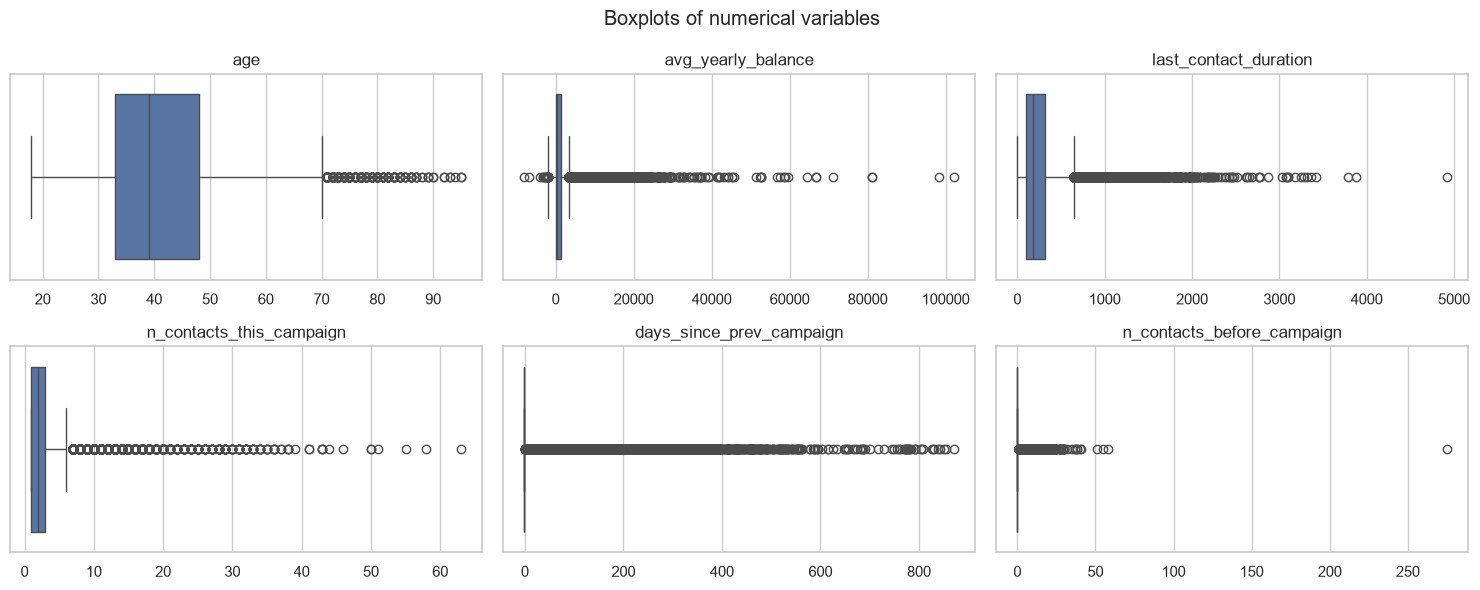

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Boxplots of numerical variables")
plt.tight_layout()
save_fig("2.6_outliers_boxplot")
plt.show()

# 3. Univariate Analysis

In [27]:
CATEGORICAL_COLS = ["job", "marital", "education", "contact_type", "prev_campaign_outcome"]
BINARY_COLS = ["has_credit_default", "has_housing_loan", "has_personal_loan"]
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

## 3.1 Numerical

In [28]:
num = df[NUMERIC_COLS]
pd.DataFrame({
    "mean": num.mean(),
    "median": num.median(),
    "mode": num.mode().iloc[0],
    "std": num.std(),
    "min": num.min(),
    "max": num.max(),
    "range": num.max() - num.min(),
    "IQR": q3 - q1,
    "skew": num.skew(),
    "kurtosis": num.kurtosis(),
}).round(2)

,mean,median,mode,std,min,max,range,IQR,skew,kurtosis
age,40.94,39.0,32,10.62,18,95,77,15.0,0.68,0.32
avg_yearly_balance,1362.27,448.0,0,3044.77,-8019,102127,110146,1356.0,8.36,140.75
last_contact_duration,258.16,180.0,124,257.53,0,4918,4918,216.0,3.14,18.15
n_contacts_this_campaign,2.76,2.0,1,3.10,1,63,62,2.0,4.90,39.25
days_since_prev_campaign,40.20,-1.0,-1,100.13,-1,871,872,0.0,2.62,6.94
n_contacts_before_campaign,0.58,0.0,0,2.30,0,275,275,0.0,41.85,4506.86


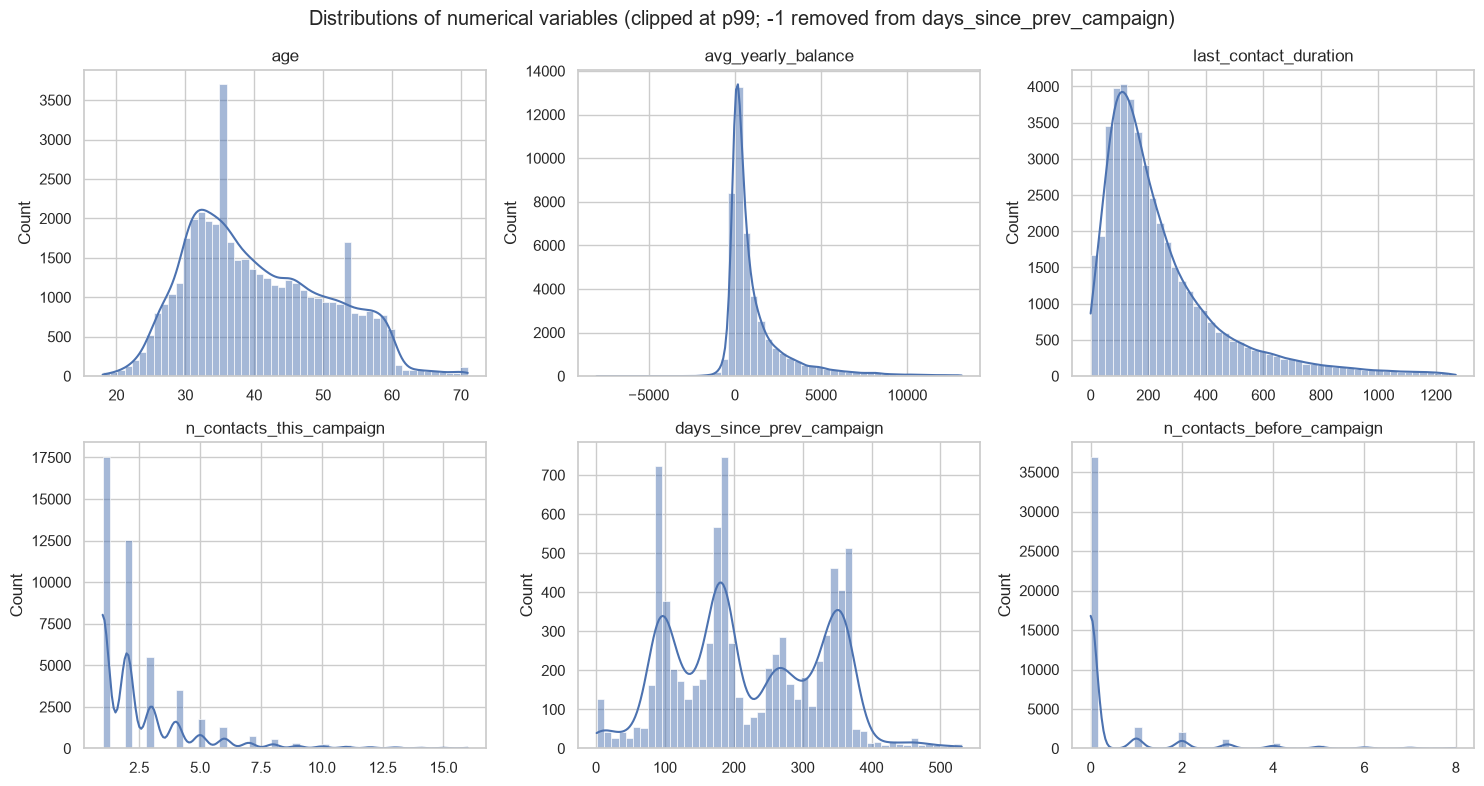

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    data = df.loc[df[col] != -1, col] if col == "days_since_prev_campaign" else df[col]  # drop -1 sentinel
    data = data[data <= data.quantile(0.99)]  # clip at p99 for readability
    sns.histplot(data, bins=50, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distributions of numerical variables (clipped at p99; -1 removed from days_since_prev_campaign)")
plt.tight_layout()
save_fig("3.1_numerical_distributions")
plt.show()

## 3.2 Datetime

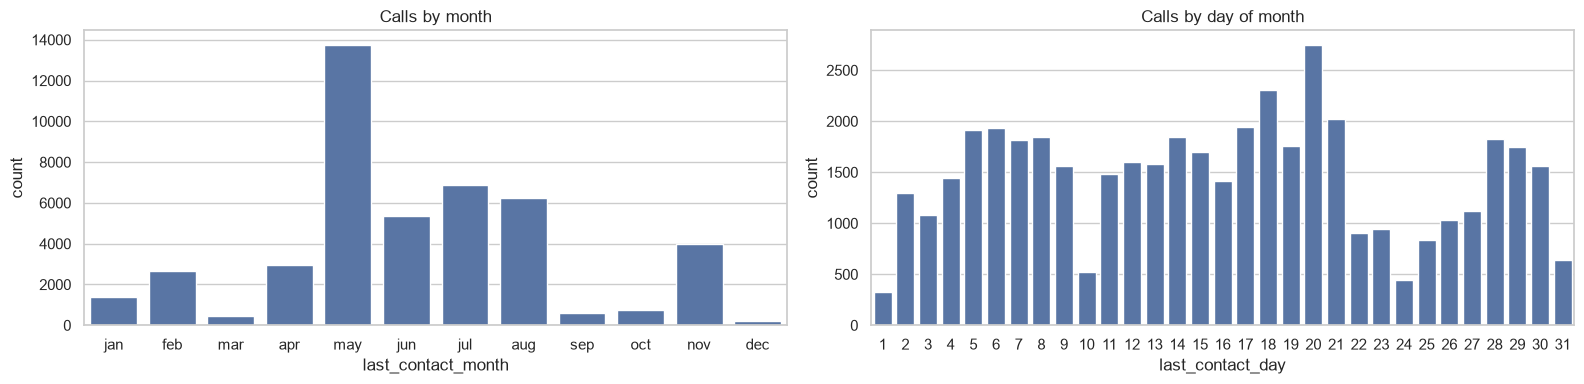

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.countplot(x=df["last_contact_month"], order=MONTH_ORDER, ax=axes[0])
sns.countplot(x=df["last_contact_day"], ax=axes[1])
axes[0].set_title("Calls by month")
axes[1].set_title("Calls by day of month")
plt.tight_layout()
save_fig("3.2_calls_by_month_and_day")
plt.show()

## 3.3 Categorical & binary

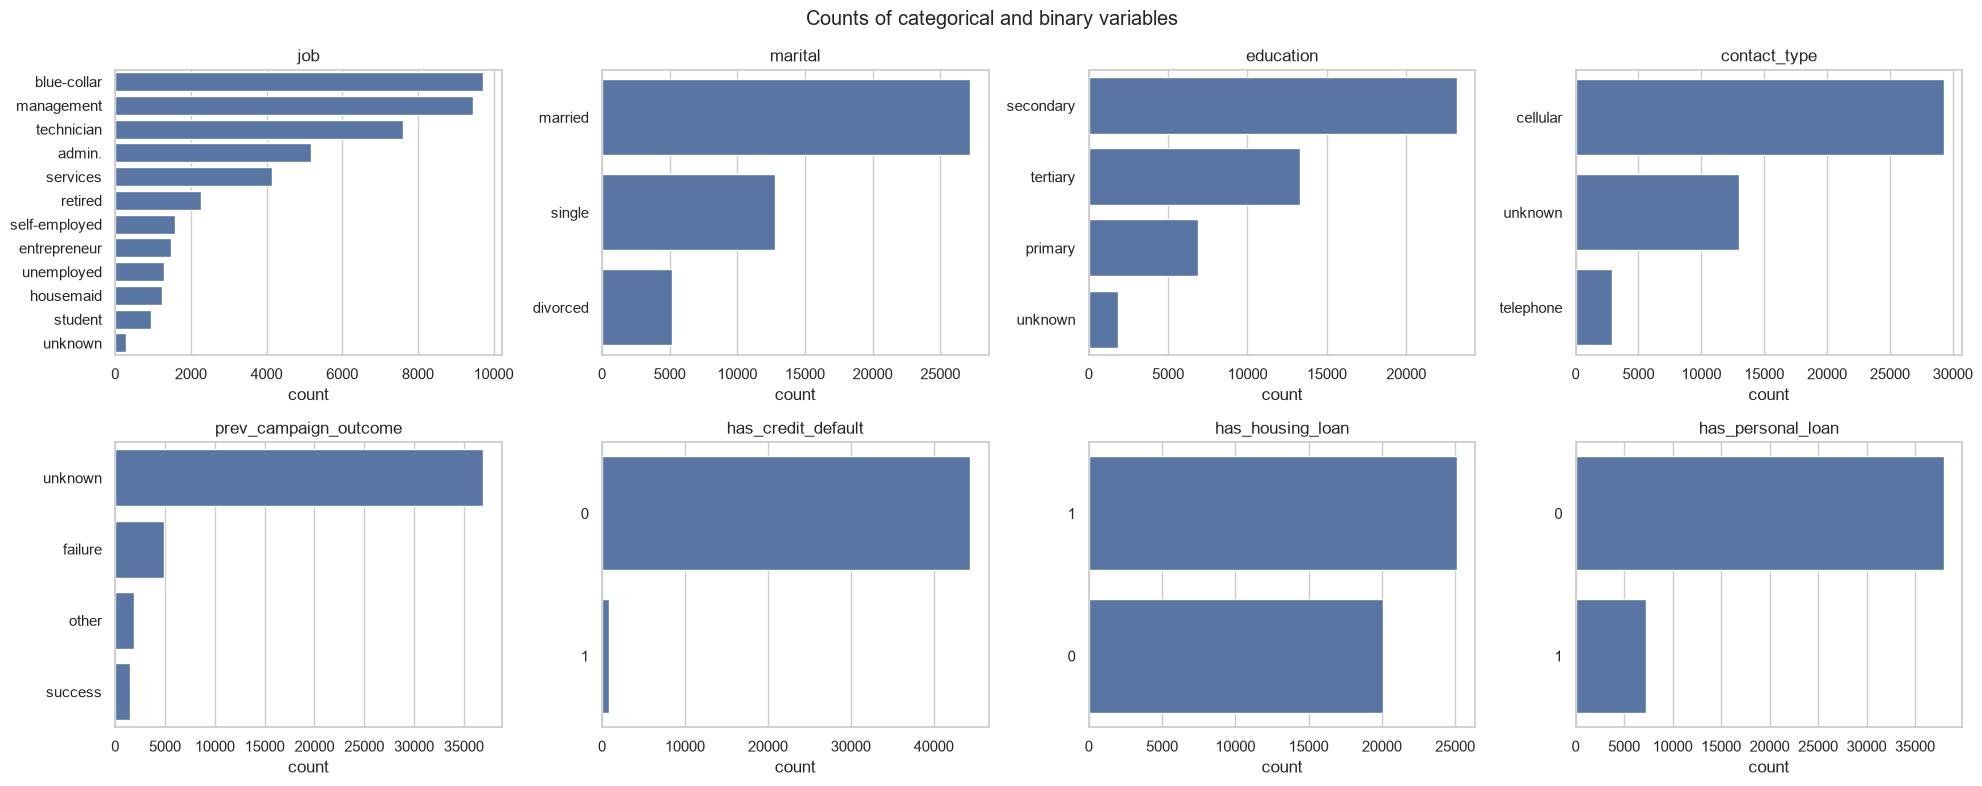

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, CATEGORICAL_COLS + BINARY_COLS):
    sns.countplot(y=df[col].astype(str), order=df[col].value_counts().index.astype(str), ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Counts of categorical and binary variables")
plt.tight_layout()
save_fig("3.3_categorical_counts")
plt.show()

In [32]:
# levels under 2% of rows
pct = pd.concat({c: df[c].value_counts(normalize=True) * 100 for c in CATEGORICAL_COLS + BINARY_COLS + ["last_contact_month"]})
pct[pct < 2].round(2)

job                 unknown    0.64
has_credit_default  1          1.80
last_contact_month  oct        1.63
                    sep        1.28
                    mar        1.06
                    dec        0.47
Name: proportion, dtype: float64

# 4. Bivariate Analysis

## 4.1 Numerical – numerical

In [33]:
PAIRS = [
    ("days_since_prev_campaign", "n_contacts_before_campaign"),
    ("age", "avg_yearly_balance"),
    ("n_contacts_this_campaign", "last_contact_duration"),
]
pd.DataFrame(
    {
        "pearson": [df[a].corr(df[b]) for a, b in PAIRS],
        "spearman": [df[a].corr(df[b], method="spearman") for a, b in PAIRS],
    },
    index=[f"{a} – {b}" for a, b in PAIRS],
).round(2)

,pearson,spearman
days_since_prev_campaign – n_contacts_before_campaign,0.45,0.99
age – avg_yearly_balance,0.10,0.10
n_contacts_this_campaign – last_contact_duration,-0.08,-0.11


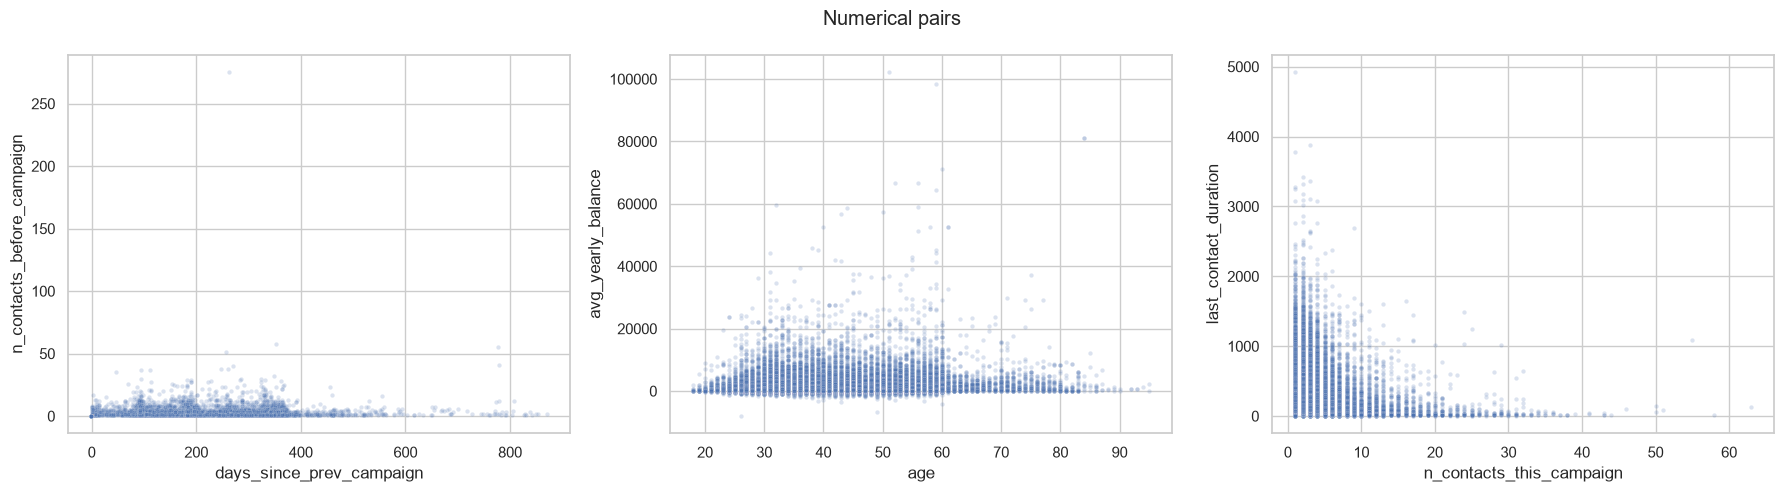

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (a, b) in zip(axes, PAIRS):
    sns.scatterplot(data=df, x=a, y=b, alpha=0.2, s=10, ax=ax)
fig.suptitle("Numerical pairs")
plt.tight_layout()
save_fig("4.1_numerical_pairs_scatter")
plt.show()

## 4.2 Numerical – categorical

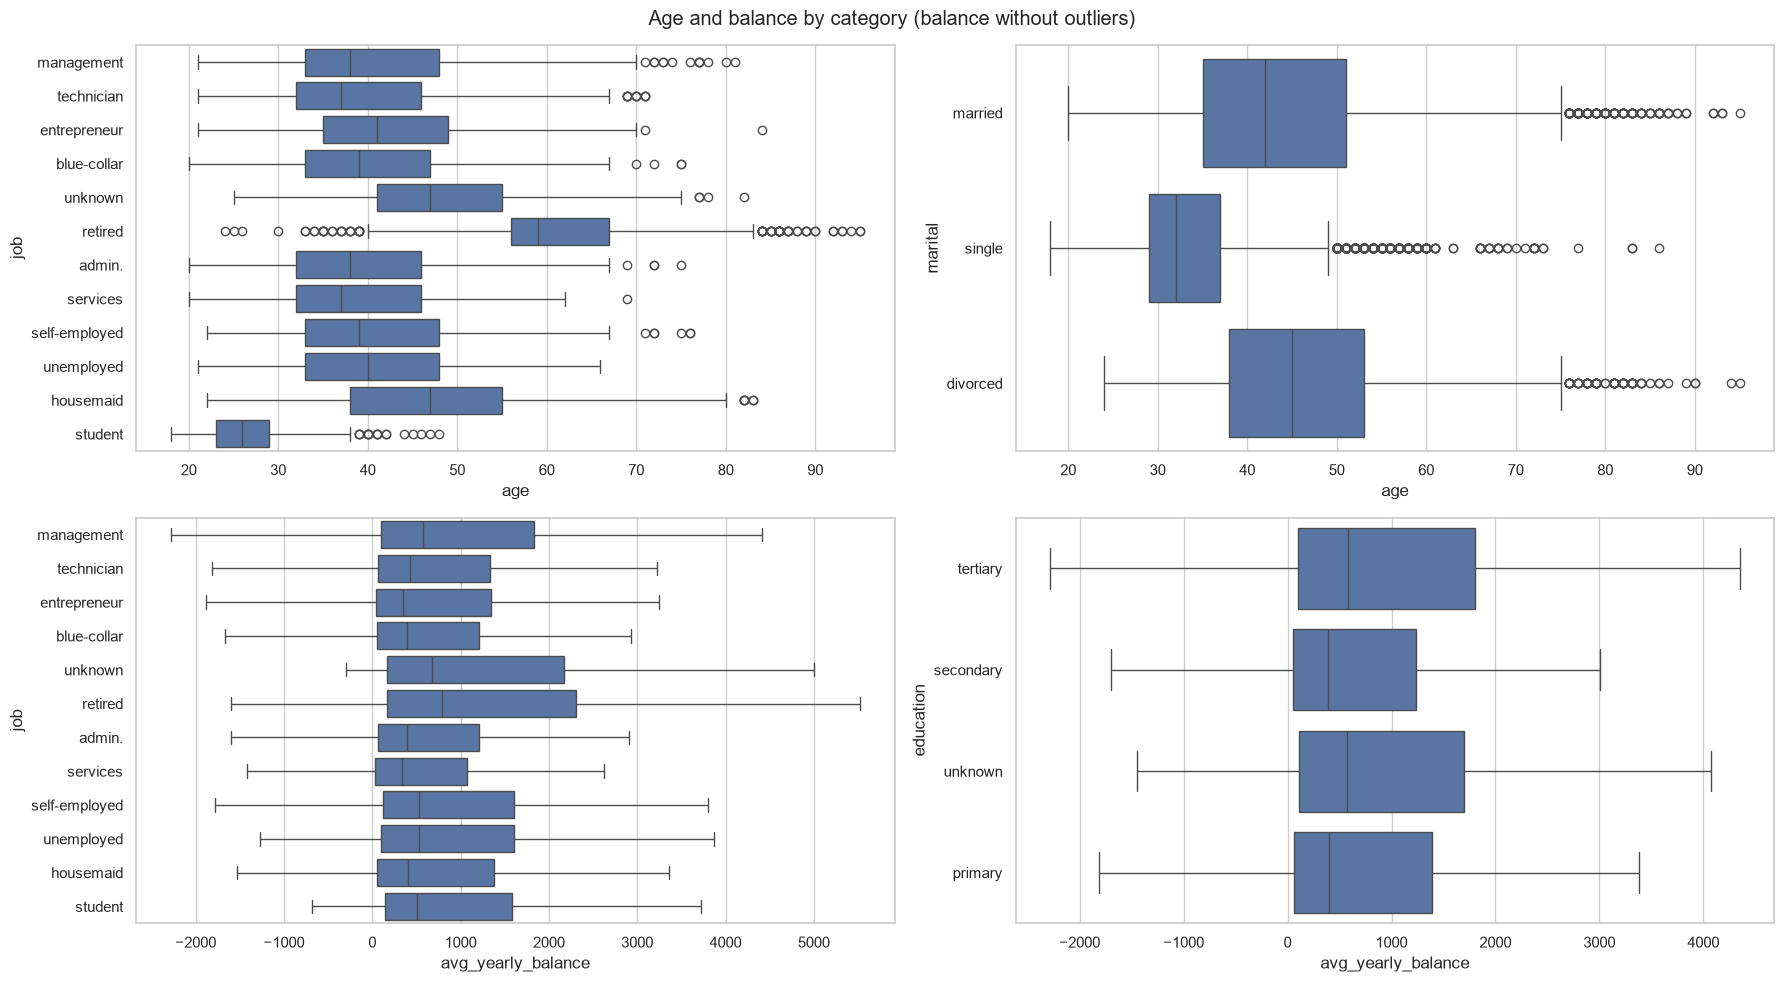

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
sns.boxplot(data=df, x="age", y="job", ax=axes[0, 0])
sns.boxplot(data=df, x="age", y="marital", ax=axes[0, 1])
sns.boxplot(data=df, x="avg_yearly_balance", y="job", showfliers=False, ax=axes[1, 0])
sns.boxplot(data=df, x="avg_yearly_balance", y="education", showfliers=False, ax=axes[1, 1])
fig.suptitle("Age and balance by category (balance without outliers)")
plt.tight_layout()
save_fig("4.2_numerical_by_category")
plt.show()

## 4.3 Categorical – categorical

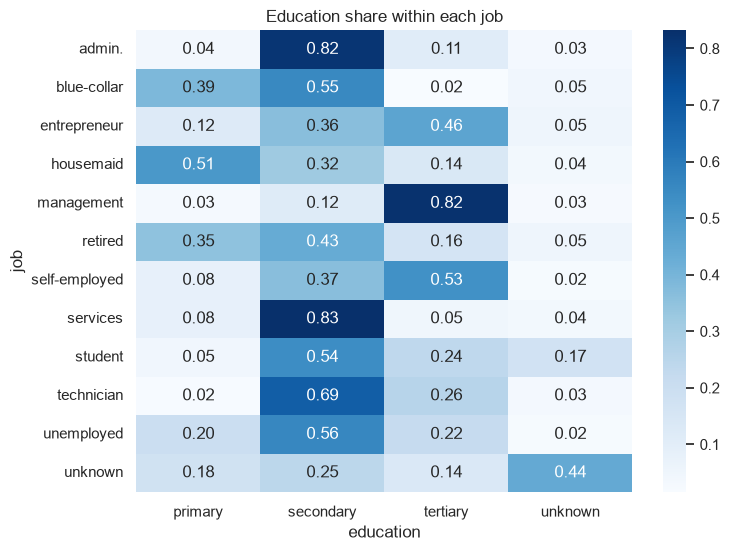

In [36]:
plt.figure(figsize=(8, 6))
sns.heatmap(pd.crosstab(df["job"], df["education"], normalize="index"), annot=True, fmt=".2f", cmap="Blues")
plt.title("Education share within each job")
save_fig("4.3_job_vs_education")
plt.show()

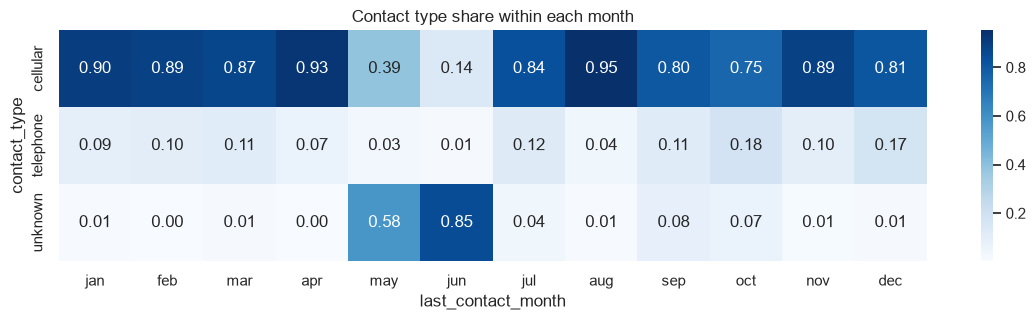

In [37]:
plt.figure(figsize=(14, 3))
sns.heatmap(pd.crosstab(df["contact_type"], df["last_contact_month"], normalize="columns")[MONTH_ORDER], annot=True, fmt=".2f", cmap="Blues")
plt.title("Contact type share within each month")
save_fig("4.3_contact_type_by_month")
plt.show()

In [38]:
pd.crosstab(df["has_housing_loan"], df["has_personal_loan"])

has_personal_loan,0,1
has_housing_loan,,
0,17204,2877
1,20763,4367


# 5. Multivariate Analysis

## 5.1 Correlation heatmap

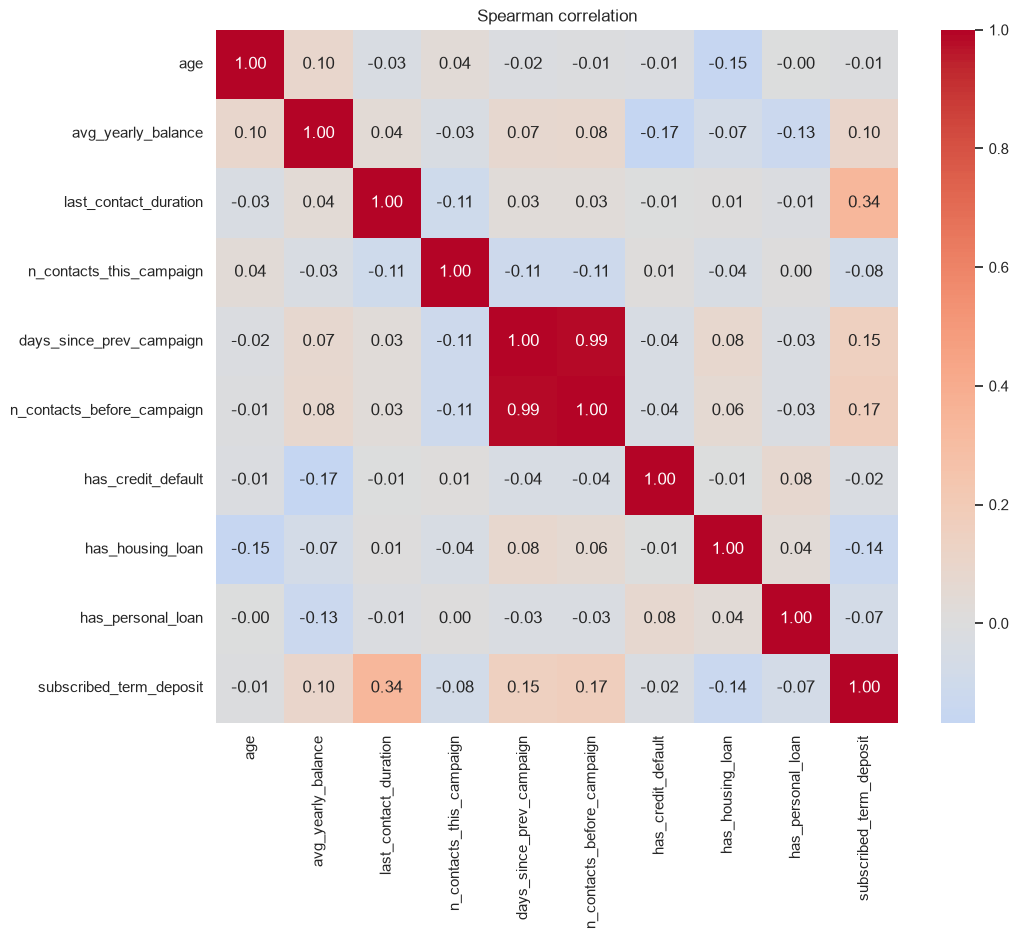

In [39]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[NUMERIC_COLS + BINARY_COLS + [TARGET]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
save_fig("5.1_correlation_heatmap")
plt.show()

## 5.2 Pairplot

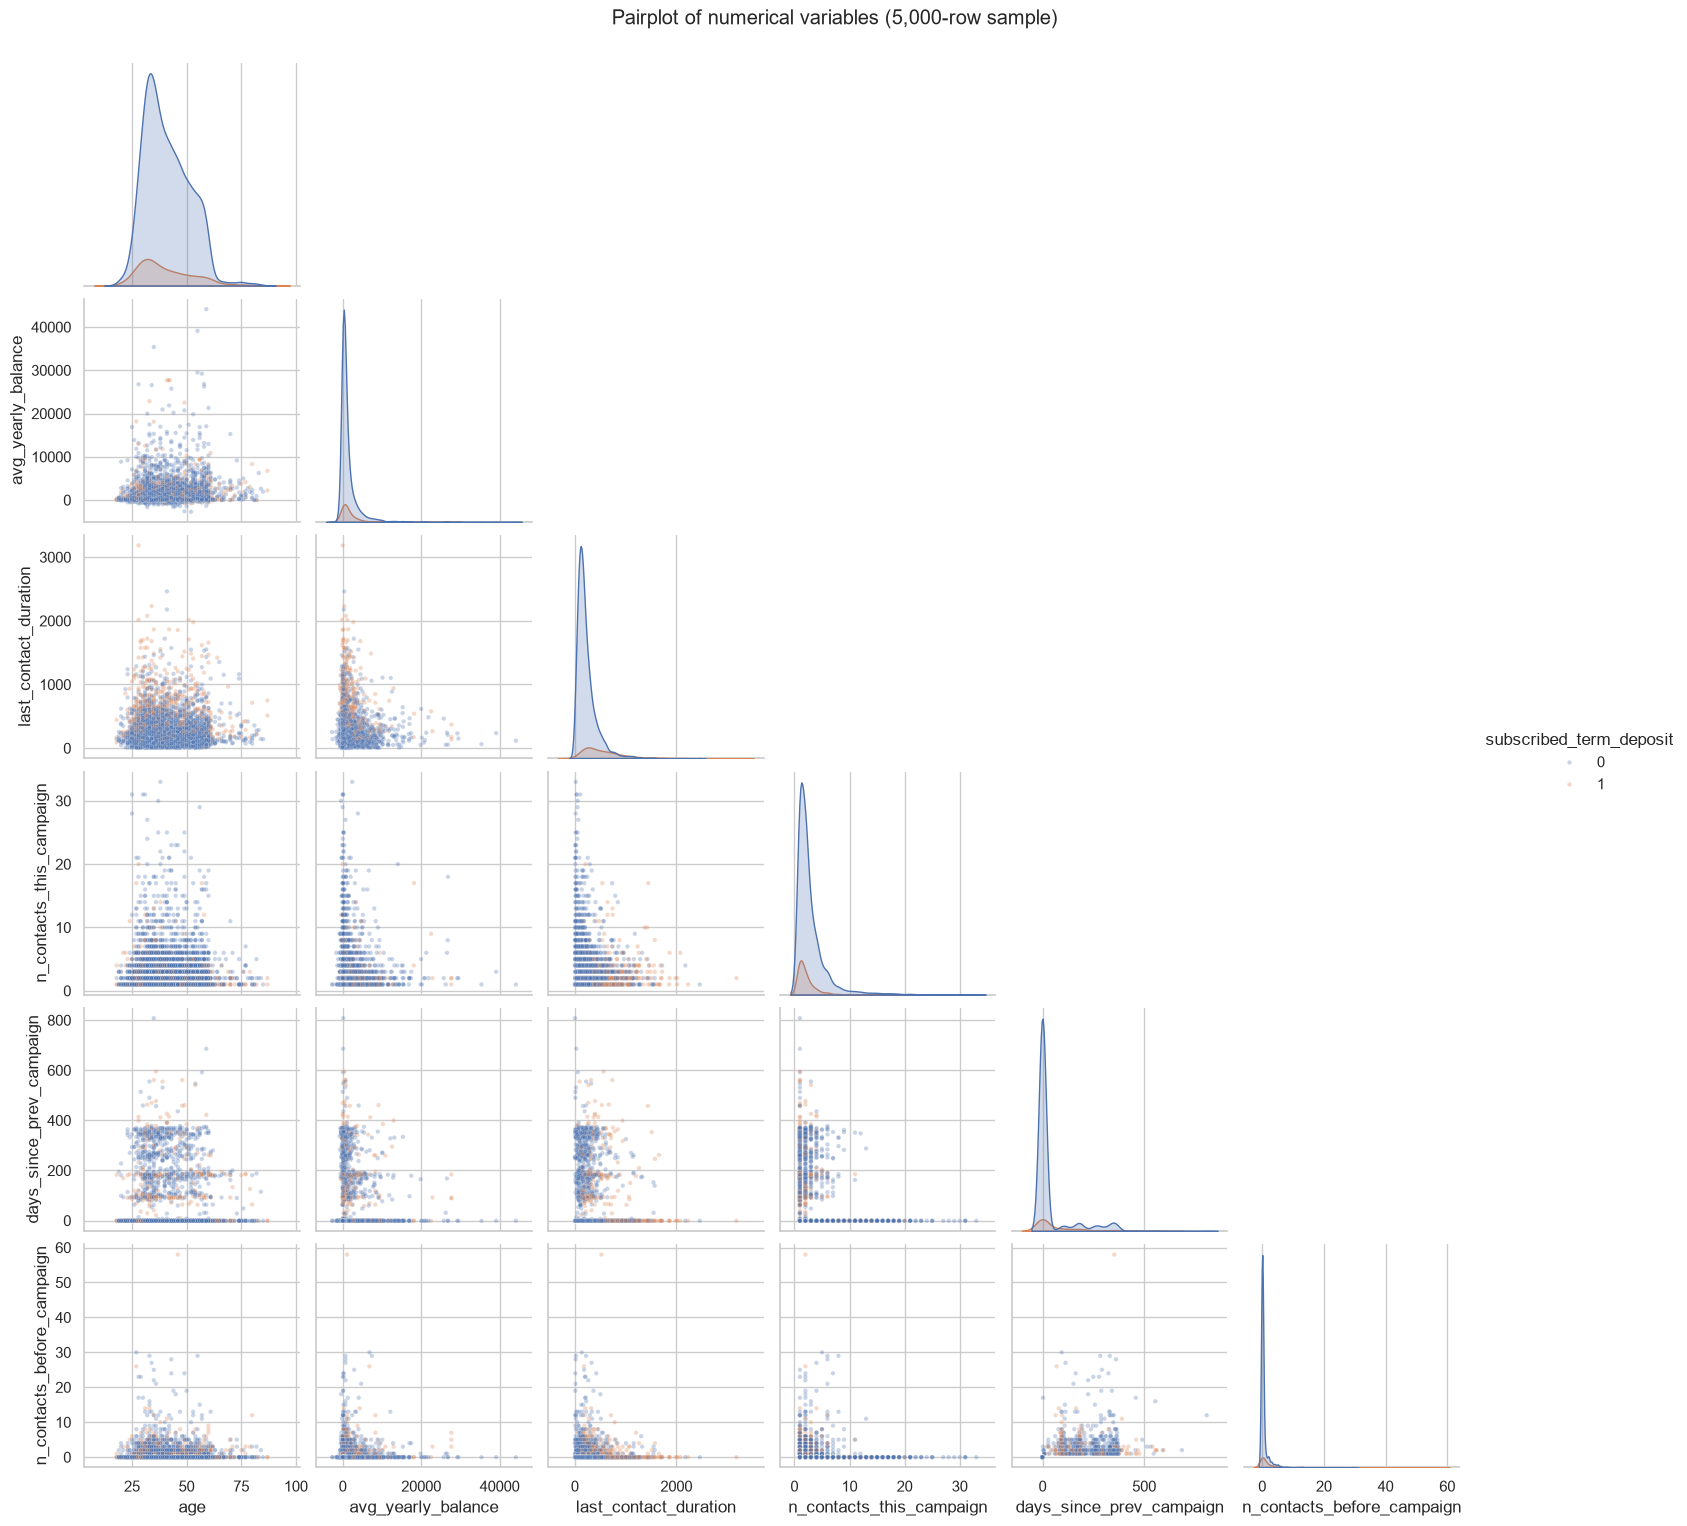

In [40]:
sample = df[NUMERIC_COLS + [TARGET]].sample(5000, random_state=RANDOM_STATE)
grid = sns.pairplot(sample, hue=TARGET, corner=True, plot_kws={"alpha": 0.3, "s": 10})
grid.figure.suptitle("Pairplot of numerical variables (5,000-row sample)", y=1.02)
save_fig("5.2_pairplot")
plt.show()

## 5.3 Pivot tables

In [41]:
# subscription rate by month × contact type
df.pivot_table(index="last_contact_month", columns="contact_type", values=TARGET, aggfunc="mean").loc[MONTH_ORDER].round(3)

contact_type,cellular,telephone,unknown
last_contact_month,,,
jan,0.102,0.093,0.111
feb,0.169,0.139,0.308
mar,0.532,0.415,0.571
apr,0.195,0.196,0.833
may,0.119,0.067,0.033
jun,0.439,0.250,0.045
jul,0.096,0.072,0.040
aug,0.109,0.130,0.098
sep,0.517,0.379,0.064


In [42]:
# subscription rate by job × age group
AGE_BINS = [17, 30, 40, 50, 60, 95]
df.groupby(["job", pd.cut(df["age"], AGE_BINS)], observed=True)[TARGET].mean().unstack().round(3)

age,"(17, 30]","(30, 40]","(40, 50]","(50, 60]","(60, 95]"
job,,,,,
admin.,0.148,0.108,0.116,0.127,0.440
blue-collar,0.111,0.066,0.066,0.062,0.308
entrepreneur,0.089,0.081,0.079,0.071,0.538
housemaid,0.119,0.069,0.072,0.073,0.375
management,0.195,0.132,0.117,0.118,0.448
retired,0.000,0.028,0.045,0.109,0.429
self-employed,0.210,0.112,0.079,0.058,0.708
services,0.112,0.092,0.071,0.079,0.000
student,0.306,0.201,0.200,NaN,NaN


## 5.4 Multicollinearity

In [43]:
# VIF = diagonal of the inverse correlation matrix
corr = df[NUMERIC_COLS + BINARY_COLS].corr()
pd.Series(np.linalg.inv(corr.values).diagonal(), index=corr.columns).sort_values(ascending=False).round(2)

days_since_prev_campaign      1.29
n_contacts_before_campaign    1.26
has_housing_loan              1.06
age                           1.04
avg_yearly_balance            1.02
n_contacts_this_campaign      1.02
has_personal_loan             1.01
has_credit_default            1.01
last_contact_duration         1.01
dtype: float64

# 6. Target-Oriented EDA

## 6.1 Class imbalance

In [44]:
(df[TARGET] == 0).sum() / (df[TARGET] == 1).sum()  # no : yes

np.float64(7.548118737001324)

## 6.2 Categorical / binary vs target

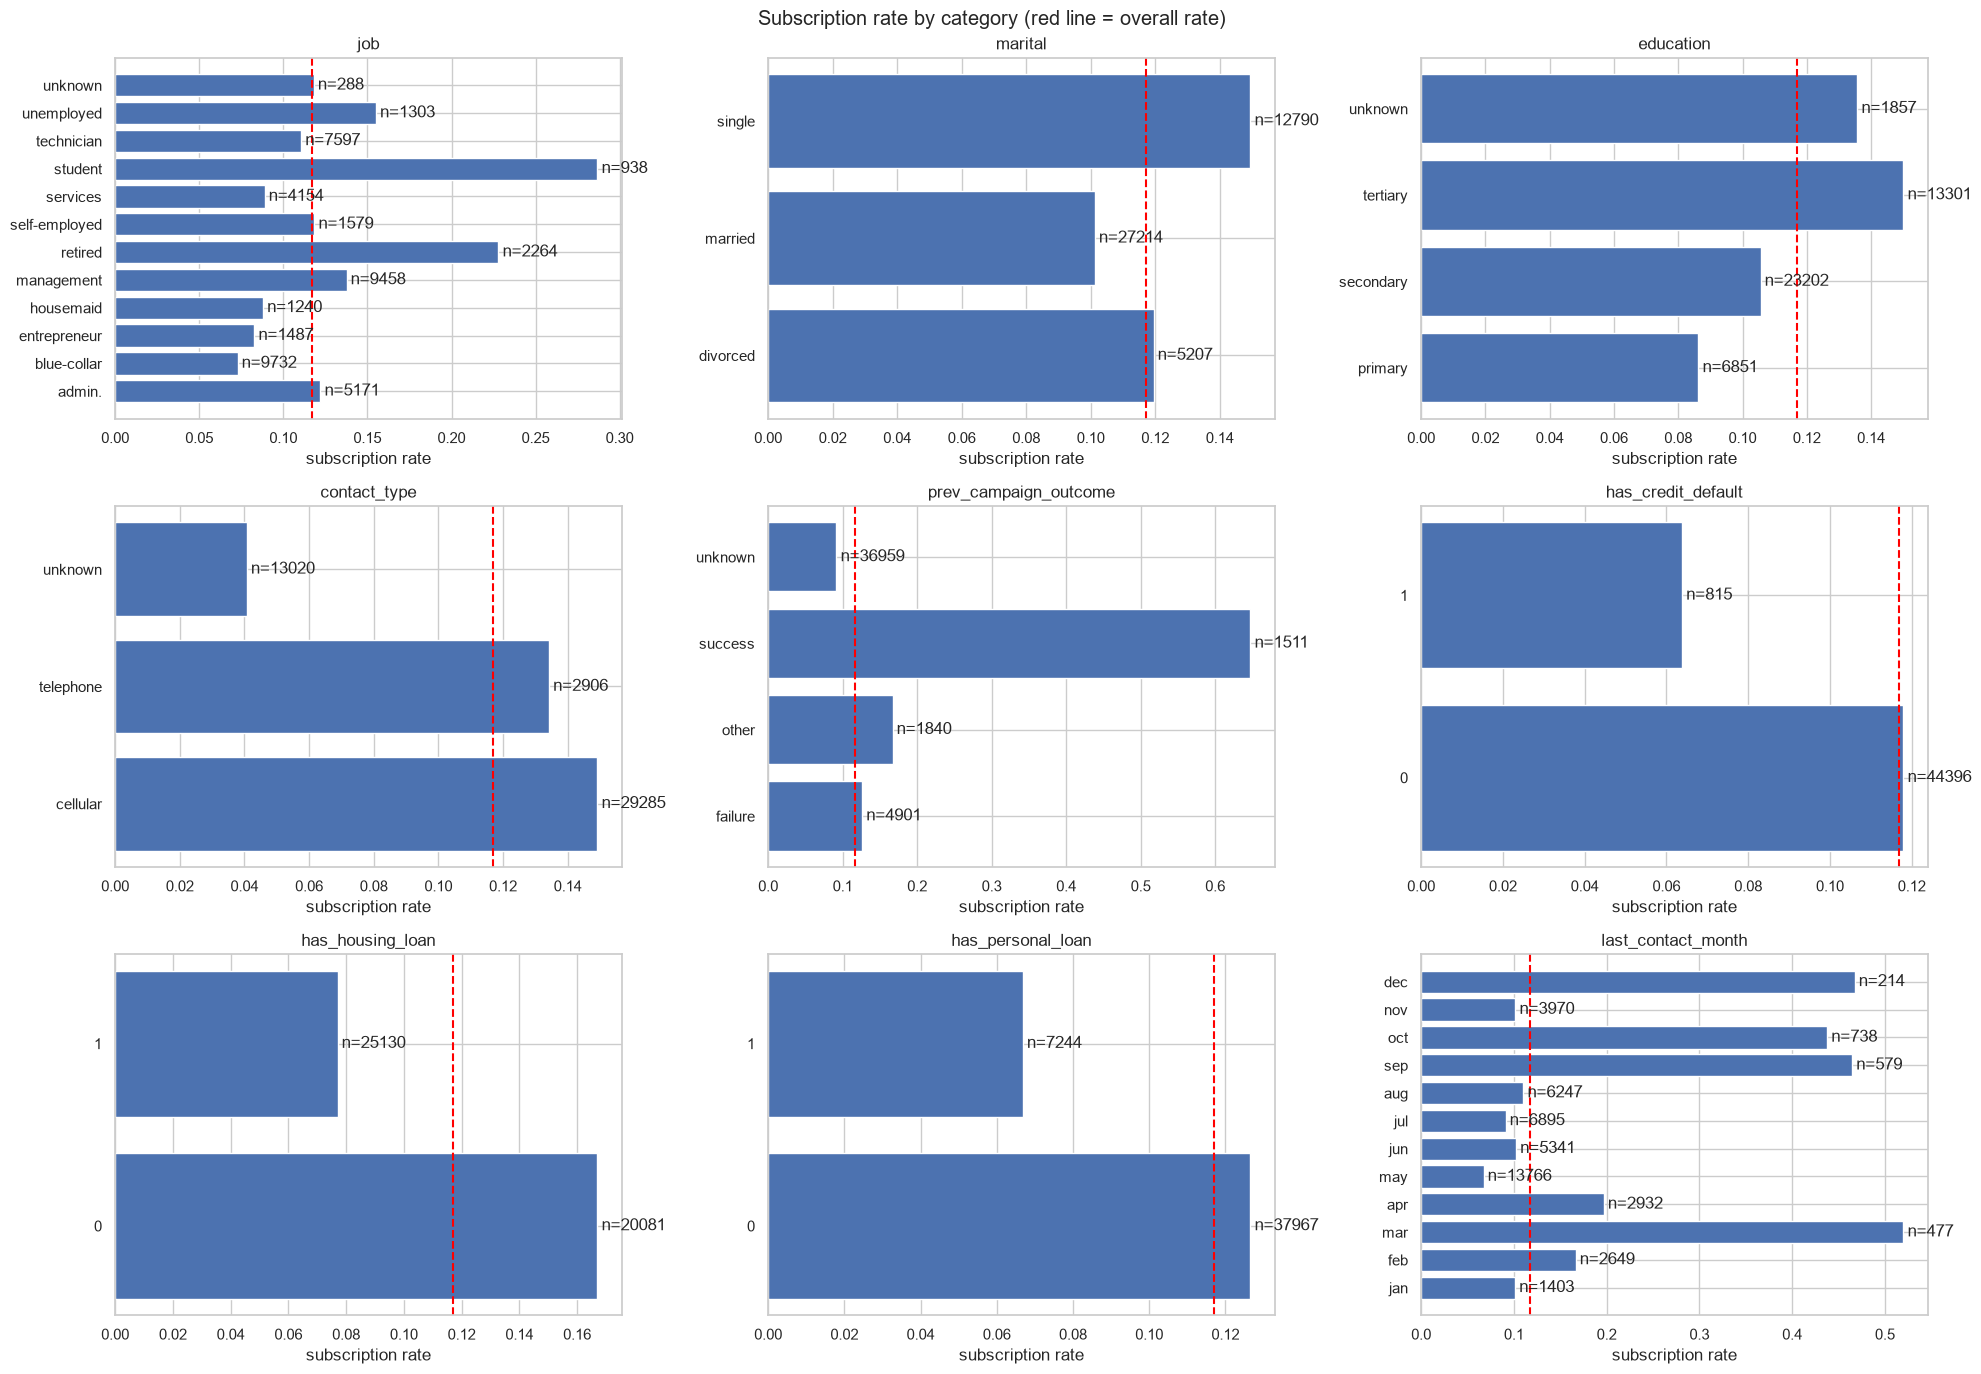

In [45]:
CAT_FEATURES = CATEGORICAL_COLS + BINARY_COLS + ["last_contact_month"]

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
for ax, col in zip(axes.flat, CAT_FEATURES):
    rate = df.groupby(col)[TARGET].agg(["mean", "size"])
    if col == "last_contact_month":
        rate = rate.loc[MONTH_ORDER]
    bars = ax.barh(rate.index.astype(str), rate["mean"])
    ax.bar_label(bars, labels=[f"n={n}" for n in rate["size"]], padding=3)
    ax.axvline(df[TARGET].mean(), color="red", linestyle="--")  # overall rate
    ax.set_title(col)
    ax.set_xlabel("subscription rate")
fig.suptitle("Subscription rate by category (red line = overall rate)")
plt.tight_layout()
save_fig("6.2_subscription_rate_by_category")
plt.show()

In [46]:
rows = {}
for col in CAT_FEATURES:
    table = pd.crosstab(df[col], df[TARGET])
    chi2, p, _, _ = chi2_contingency(table)
    rows[col] = {"chi2": chi2, "p_value": p, "cramers_v": np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))}
pd.DataFrame(rows).T.sort_values("cramers_v", ascending=False).round(4)

,chi2,p_value,cramers_v
prev_campaign_outcome,4391.5066,0.0,0.3117
last_contact_month,3061.8389,0.0,0.2602
contact_type,1035.7142,0.0,0.1514
has_housing_loan,874.8224,0.0,0.1391
job,836.1055,0.0,0.1360
education,238.9235,0.0,0.0727
has_personal_loan,209.6170,0.0,0.0681
marital,196.4959,0.0,0.0659
has_credit_default,22.2022,0.0,0.0222


## 6.3 Numerical vs target

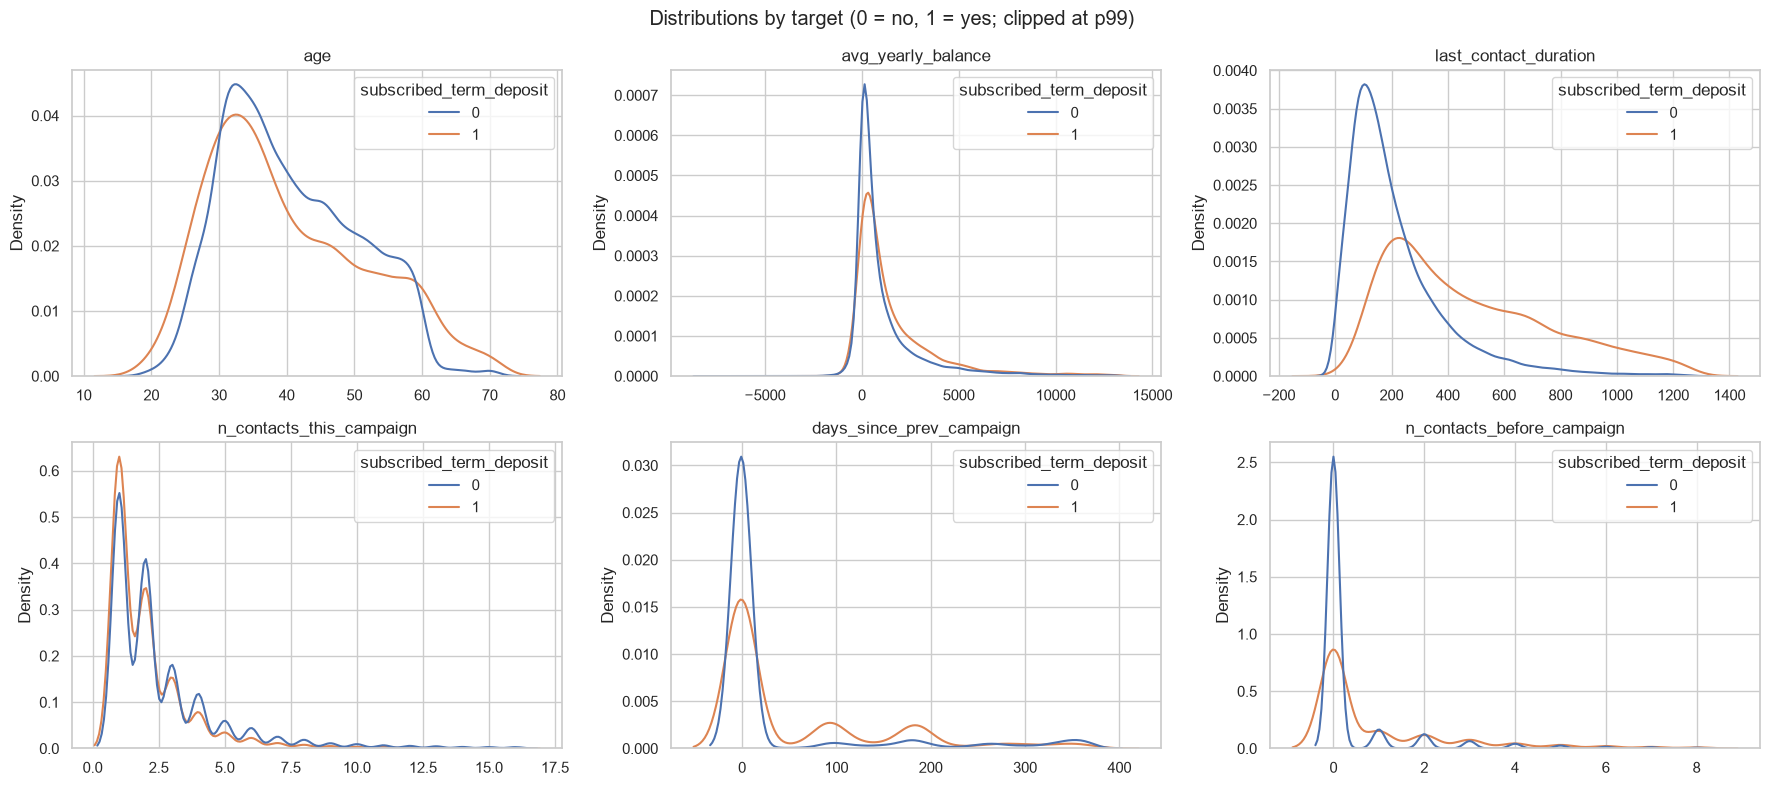

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    data = df[df[col] <= df[col].quantile(0.99)]  # clip at p99 for readability
    sns.kdeplot(data=data, x=col, hue=TARGET, common_norm=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distributions by target (0 = no, 1 = yes; clipped at p99)")
plt.tight_layout()
save_fig("6.3_numerical_by_target")
plt.show()

In [48]:
rows = {}
for col in NUMERIC_COLS:
    no, yes = df.loc[df[TARGET] == 0, col], df.loc[df[TARGET] == 1, col]
    rows[col] = {"median_0": no.median(), "median_1": yes.median(), "p_value": mannwhitneyu(no, yes).pvalue}
pd.DataFrame(rows).T

,median_0,median_1,p_value
age,39.0,38.0,6.281791e-02
avg_yearly_balance,417.0,733.0,6.593846e-101
last_contact_duration,164.0,426.0,0.000000e+00
n_contacts_this_campaign,2.0,2.0,1.948490e-71
days_since_prev_campaign,-1.0,-1.0,2.484118e-235
n_contacts_before_campaign,0.0,0.0,3.491824e-283


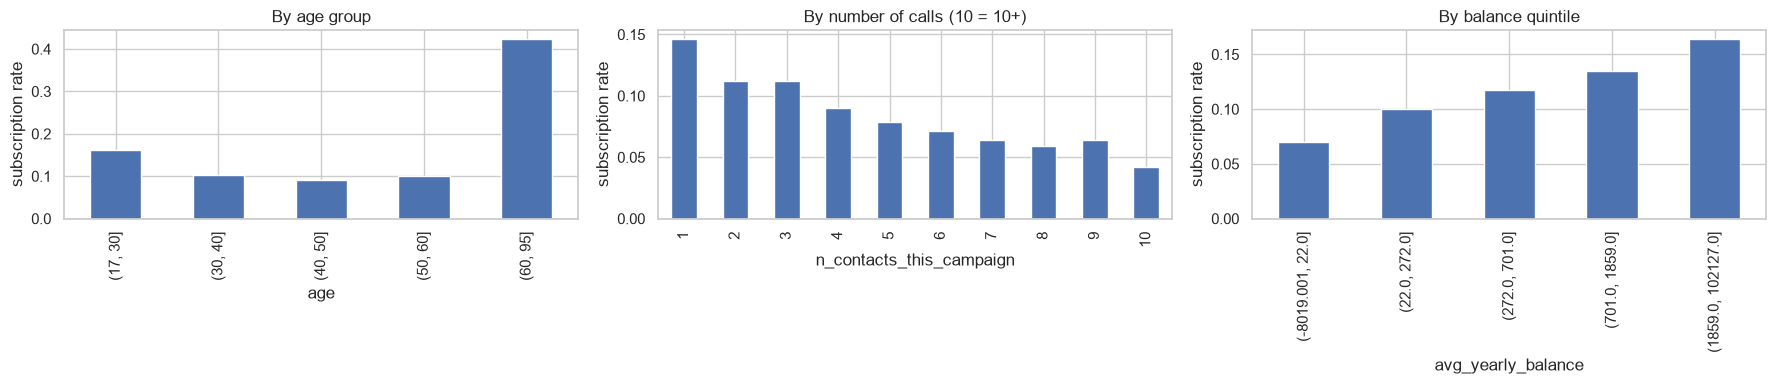

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df.groupby(pd.cut(df["age"], AGE_BINS), observed=True)[TARGET].mean().plot.bar(ax=axes[0], title="By age group")
df.groupby(df["n_contacts_this_campaign"].clip(upper=10))[TARGET].mean().plot.bar(ax=axes[1], title="By number of calls (10 = 10+)")
df.groupby(pd.qcut(df["avg_yearly_balance"], 5), observed=True)[TARGET].mean().plot.bar(ax=axes[2], title="By balance quintile")
for ax in axes:
    ax.set_ylabel("subscription rate")
plt.tight_layout()
save_fig("6.3_subscription_rate_by_bins")
plt.show()

## 6.4 Feature ranking

In [50]:
features = df.drop(columns=TARGET).copy()
for col in features.select_dtypes(exclude="number").columns:
    features[col] = features[col].astype("category").cat.codes

mi = mutual_info_classif(
    features,
    df[TARGET],
    discrete_features=[c not in NUMERIC_COLS for c in features.columns],
    random_state=RANDOM_STATE,
)
pd.Series(mi, index=features.columns).sort_values(ascending=False).round(4)

last_contact_duration         0.0725
prev_campaign_outcome         0.0294
days_since_prev_campaign      0.0272
last_contact_month            0.0244
avg_yearly_balance            0.0209
age                           0.0145
contact_type                  0.0136
n_contacts_before_campaign    0.0119
has_housing_loan              0.0097
job                           0.0083
n_contacts_this_campaign      0.0069
last_contact_day              0.0061
has_personal_loan             0.0026
education                     0.0026
marital                       0.0021
has_credit_default            0.0003
dtype: float64

## 6.5 Time factor

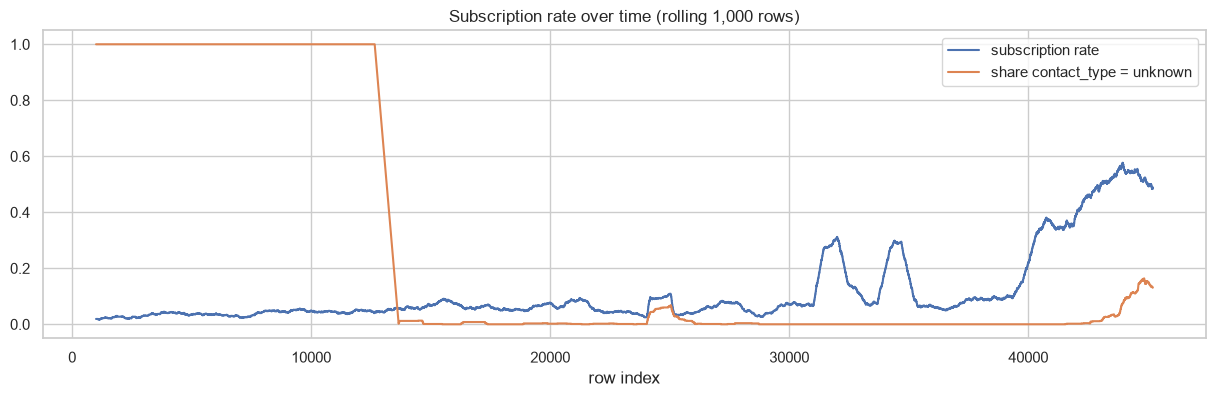

In [51]:
# rows are in time order (05/2008 – 11/2010)
ax = df[TARGET].rolling(1000).mean().plot(figsize=(15, 4), label="subscription rate")
(df["contact_type"] == "unknown").rolling(1000).mean().plot(ax=ax, label="share contact_type = unknown")
ax.set_title("Subscription rate over time (rolling 1,000 rows)")
ax.set_xlabel("row index")
ax.legend()
save_fig("6.5_time_drift")
plt.show()

## 6.6 Leakage: `last_contact_duration`

In [52]:
df.groupby(pd.qcut(df["last_contact_duration"], 10), observed=True)[TARGET].mean().round(3)

last_contact_duration
(-0.001, 58.0]     0.002
(58.0, 89.0]       0.012
(89.0, 117.0]      0.028
(117.0, 147.0]     0.046
(147.0, 180.0]     0.068
(180.0, 223.0]     0.090
(223.0, 280.0]     0.123
(280.0, 368.0]     0.138
(368.0, 548.0]     0.209
(548.0, 4918.0]    0.455
Name: subscribed_term_deposit, dtype: float64